## Calculate b by Custom class

In [36]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np

In [37]:
x,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20)

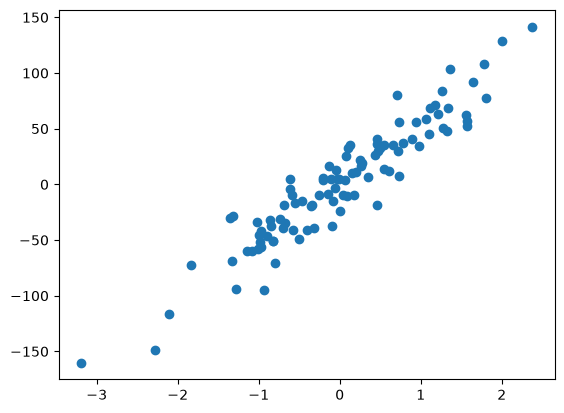

In [38]:
plt.scatter(x,y)

In [39]:
from sklearn.linear_model import LinearRegression

In [40]:
lr = LinearRegression()

In [41]:
lr.fit(x,y)
print(lr.coef_)
print(lr.intercept_)

[51.43604196]
0.9203906398165083


In [43]:
m = 51.43

In [50]:
class GDRegressor:
    def __init__(self, learning_rate, epochs):
        self.m = m
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs

    def fit(self, x, y):
        # Calculate the b using GD
        for i in range(self.epochs):
            loss_slope = -2 * np.sum(y - self.m * x.ravel() - self.b)
            self.b = self.b - (self.lr * loss_slope)
            print(loss_slope, self.b)

        print(self.b)

In [55]:
gd = GDRegressor(0.001, 50)

In [ ]:
gd.fit(x, y)

## Calculate b and m by custom class

In [57]:
from sklearn.model_selection import cross_val_score

In [59]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)

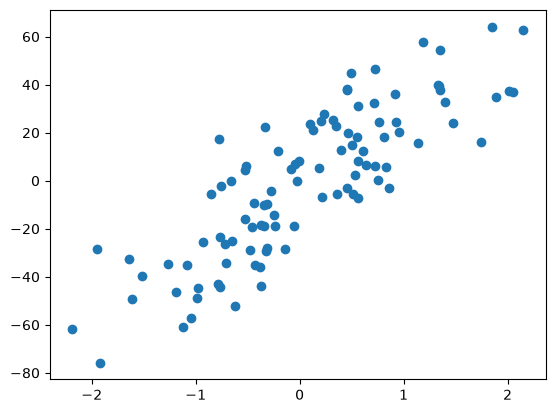

In [60]:
plt.scatter(X,y)

In [61]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [62]:
lr = LinearRegression()

In [63]:
lr.fit(X_train,y_train)
print(lr.coef_)
print(lr.intercept_)

[28.12597332]
-2.2710144261783825


In [64]:
y_pred = lr.predict(X_test)
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)

0.6345158782661012

In [65]:
class GDRegressor:
    
    def __init__(self,learning_rate,epochs):
        self.m = 100
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs
        
    def fit(self,X,y):
        # calcualte the b using GD
        for i in range(self.epochs):
            loss_slope_b = -2 * np.sum(y - self.m*X.ravel() - self.b)
            loss_slope_m = -2 * np.sum((y - self.m*X.ravel() - self.b)*X.ravel())
            
            self.b = self.b - (self.lr * loss_slope_b)
            self.m = self.m - (self.lr * loss_slope_m)
        print(self.m,self.b)
        
    def predict(self,X):
        return self.m * X + self.b

In [66]:
gd = GDRegressor(0.001,50)

In [67]:
gd.fit(X_train,y_train)

28.159367347119066 -2.3004574196824854


In [68]:
y_pred = gd.predict(X_test)
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)

0.6343842836315579